# Azure ML + MLflow: from a notebook to a tracked command job

**Carlos Falconi · Microsoft Learn practice**

This notebook explains the small experiment implemented in `src/train.py`.
It adapts [this Microsoft Learn module](https://learn.microsoft.com/en-us/training/modules/run-training-scripts-track-models-mlflow/): a parameterized script, an Azure ML command job, and MLflow tracking.

The data and models are deliberately small. The point is to understand the lifecycle, not to make a medical prediction service. Local cells can run immediately. Cloud submission is a separate, explicit step.

**Recorded cloud execution:** a completed two-core Azure command job and registered model version 1 are documented in [the execution evidence](../evidence/README.md). The outputs in this notebook are from local execution; the cloud submission cells stay disabled.

## 1. Import the tools

`scikit-learn` handles learning. `MLflow` records what was trained and how it performed. The Azure SDK later sends exactly the same training script to cloud compute.

In [1]:
from pathlib import Path
import json
import os
import sys

import mlflow
import mlflow.sklearn
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "scripts"))
from train import build_candidates, split_data, train


## 2. Split before preprocessing

The dataset has 442 rows and 10 numeric features. Its target is continuous, so this is **regression**. `scaled=False` avoids using a dataset-wide scaler. The Ridge pipeline will learn its scaler using training rows only.

The random split assumes independent rows. For a time-dependent prediction problem, we would instead split chronologically. Adding a month feature would not make a random split appropriate.

In [2]:
features, target, split = split_data(seed=42)
print(f"Rows: {len(features)}, features: {features.shape[1]}")
pd.DataFrame({"partition": split.keys(), "rows": [len(ids) for ids in split.values()]})


Rows: 442, features: 10


,partition,rows
0,train,264
1,validation,89
2,test,89


## 3. Choose two simple candidates

Ridge is a regularized linear model. Random Forest averages many trees and can capture nonlinear patterns. Both see the same training and validation rows. We also compute a mean-prediction baseline.

**MAE** is the main metric: average absolute error in target units. Lower is better. We do not use the test set to choose between candidates.

In [3]:
candidates = build_candidates(seed=42, ridge_alpha=1.0, trees=100)
for name, estimator in candidates.items():
    print(name, "->", estimator)


ridge -> Pipeline(steps=[('standardscaler', StandardScaler()), ('ridge', Ridge())])
random_forest -> RandomForestRegressor(max_depth=5, min_samples_leaf=5, n_jobs=1,
                      random_state=42)


## 4. Run the parameterized training code locally

The script opens a parent MLflow run and two nested candidate runs. It logs parameters, validation metrics and candidate models, then selects by validation MAE. Only the winner is refitted on train + validation and evaluated on test.

The cell reuses an existing notebook result to avoid accidental reruns. To conduct another experiment, use a new output directory and keep test data out of selection decisions.

In [4]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("learn-mlflow-regression-local")
output_dir = ROOT / "outputs" / "notebook"
if (output_dir / "summary.json").exists():
    summary = json.loads((output_dir / "summary.json").read_text())
    print("Loaded the existing notebook run.")
else:
    summary = train(output_dir, output_dir / "model", seed=42, ridge_alpha=1.0, trees=100)


{
  "executed_at_utc": "2026-10-12T20:35:24.566305+00:00",
  "execution": "local",
  "parent_run_id": "0f2c0fecac9441f4af9d2d7254e7b40b",
  "dataset": "scikit-learn diabetes (raw features)",
  "seed": 42,
  "split_rows": {
    "train": 264,
    "validation": 89,
    "test": 89
  },
  "baseline_validation_mae": 64.12878787878789,
  "candidates": [
    {
      "model": "ridge",
      "run_id": "1bb36a64262e4ebba718427b0a1f3ed4",
      "validation_mae": 42.723049673477995,
      "validation_rmse": 51.10314502902912,
      "validation_r2": 0.5233405615503286
    },
    {
      "model": "random_forest",
      "run_id": "53b41e20c33644d1a5f78e74ac659cc1",
      "validation_mae": 43.36157150576585,
      "validation_rmse": 53.916747259812944,
      "validation_r2": 0.4694084768510236
    }
  ],
  "selected_model": "ridge",
  "selection_rule": "lowest validation MAE; test excluded from selection",
  "test_metrics": {
    "mae": 42.811999418348904,
    "rmse": 53.7774540653439,
    "r2": 0.4541

## 5. Compare validation results, then inspect the held-out result

The two validation scores are comparable because the split is identical. The final test score describes the selected model **after refitting on more data**. It is not used to choose or tune a model.

,model,validation_mae,validation_rmse,validation_r2
0,ridge,42.723050,51.103145,0.523341
1,random_forest,43.361572,53.916747,0.469408


Mean baseline validation MAE: 64.13
Selected model: ridge


,mae,rmse,r2
final test,42.811999,53.777454,0.454147


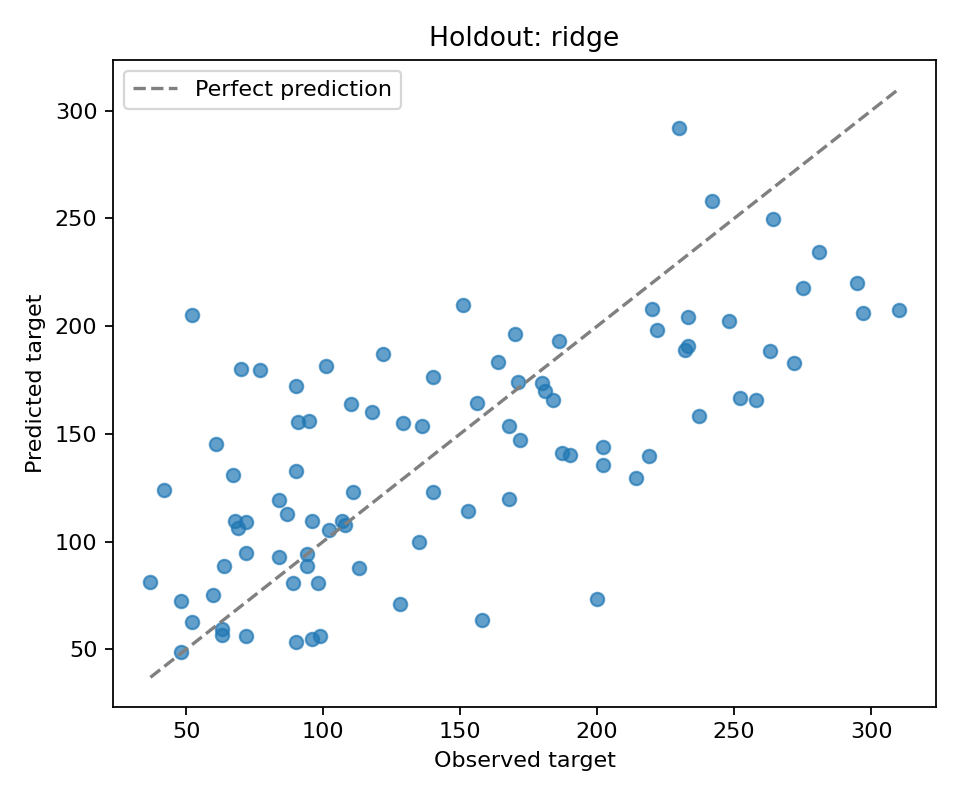

In [5]:
display(pd.DataFrame(summary["candidates"]).drop(columns="run_id"))
print("Mean baseline validation MAE:", round(summary["baseline_validation_mae"], 2))
print("Selected model:", summary["selected_model"])
display(pd.DataFrame([summary["test_metrics"]], index=["final test"]))
display(Image(filename=str(output_dir / "test_predictions.png")))


## 6. Reload the saved MLflow model

The saved folder contains the estimator, model metadata, dependency information, an input example and a signature. The signature describes the expected input columns and output type. Reloading the model checks that it can be used independently of the training object.

In [6]:
saved_model = mlflow.sklearn.load_model(str(output_dir / "model"))
example = features.iloc[:3]
pd.DataFrame({"prediction": saved_model.predict(example)})


,prediction
0,209.900836
1,70.132221
2,183.218357


## 7. Configure an Azure ML command job

`code` is the directory uploaded to Azure; `command` is the script to execute; `environment` defines its packages; `compute` identifies where it runs. Only `src/` is uploaded, so local configuration and credentials stay outside the job snapshot.

The job uses one CPU instance and a ten-minute execution timeout. The timeout is not a spending cap. A workspace and permitted compute must already be available. No workspace or endpoint is created by this notebook.

In [7]:
from dotenv import load_dotenv
from submit_job import build_job, register_model, wait_for_job, workspace_client

load_dotenv(ROOT / ".env")
compute_name = os.getenv("AZURE_ML_COMPUTE") or "YOUR_EXISTING_CPU_COMPUTE"
job = build_job(compute_name)
print("Training command:", job.command)
print("Experiment:", job.experiment_name)
print("Time limit (seconds):", job.limits.timeout)


Training command: python train.py --seed 42 --ridge-alpha 1.0 --trees 100 --output-dir outputs --model-output ${{outputs.model}}
Experiment: learn-mlflow-regression
Time limit (seconds): 600


## 8. Submit only when the account and cost settings are ready

Sign in with `az login` and fill in `.env` first. `DefaultAzureCredential` uses that sign-in. Azure ML automatically supplies the MLflow tracking URI inside the training job.

Change `SUBMIT_TO_AZURE` to `True` only when ready. Leave it `False` when reading or running all cells locally. Serverless execution is also available through the CLI in the README.

In [8]:
SUBMIT_TO_AZURE = False
submitted = None
client = None

if SUBMIT_TO_AZURE:
    client = workspace_client()
    submitted = client.jobs.create_or_update(job)
    print("Job name:", submitted.name)
    print("Open this run in Azure ML Studio:", submitted.studio_url)
    wait_for_job(client, submitted.name, {"job_name": submitted.name})
else:
    print("Cloud submission is disabled. Inspect the job and resource settings first.")


Cloud submission is disabled. Inspect the job and resource settings first.


## 9. Register a completed model

Registration creates a versioned **model asset** in the workspace. It does not deploy an API, reserve serving compute, or prove that the model is ready for production. The helper checks that the job completed before registering its named MLflow model output.

In [9]:
REGISTER_MODEL = False

if REGISTER_MODEL and submitted is not None:
    registered = register_model(client, submitted.name)
    print("Registered:", registered.name, "version", registered.version)
else:
    print("Registration is disabled or no cloud job was submitted in this session.")


Registration is disabled or no cloud job was submitted in this session.


## 10. Explain the experiment in your own words

1. Why do train, validation and test serve different purposes?
2. Where is the scaler fitted, and why does that prevent leakage?
3. Why is MAE appropriate here, while accuracy is not?
4. What belongs to Azure ML, and what belongs to MLflow?
5. What changes when this script runs as a cloud command job?
6. How is model registration different from deploying an endpoint?
7. What would need to change before using this approach on temporal or production data?

**Sources:** [Microsoft Learn module](https://learn.microsoft.com/en-us/training/modules/run-training-scripts-track-models-mlflow/), [official hosted lab](https://microsoftlearning.github.io/mslearn-mlops/docs/02-optimize-model-training.html), [scikit-learn dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).
